<a href="https://colab.research.google.com/github/ChristopheGraveline064/ADVENT/blob/master/cda_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TODO:
1.   Lower MAE
2.   Synthetic Data
3.   Fine Tuning

#Load Data

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np
import os
import tensorflow as tf

datapath = '/content/drive/MyDrive/aerostick_data/'
df_feature_file = {}
df_target_file = {}

# Load CSV
for filename in os.listdir(datapath):
  #N.B details = features when naming files
  if filename.endswith('.csv') and filename.startswith('tmp-det_'):
    print(f'load {filename}')
    df_feature = pd.read_csv(os.path.join(datapath, filename))
    df_feature_file[filename] = df_feature
    print(df_feature.shape)

for filename in os.listdir(datapath):
  if filename.endswith('.csv') and filename.startswith('tmp-sum_'):
    print(f'load {filename}')
    df_target =  pd.read_csv(os.path.join(datapath, filename), header=None) #Target files do no countain a header
    #Drop the fist two columns that contains index and test name
    df_target = df_target.drop(columns=[df_target.columns[0],df_target.columns[1]])
    df_target_file[filename] = df_target
    print(df_target.shape)


load tmp-det__=TireTest_Sat Jul 26 083913 2025.csv
(3117, 5)
load tmp-det_AI1__=TireTest_Sat Jul 26 083913 2025.csv
(3117, 6)
load tmp-det_AI2__=TireTest_Fri Jul 25 052355 2025.csv
(2797, 6)
load tmp-det_AI3__=TireTest_Tue Jul 22 094322 2025.csv
(3770, 6)
load tmp-det_AI4__=TireTest_Mon Jul 21 095619 2025.csv
(3629, 6)
load tmp-det___=MG2025-1_Tue Aug 5 06:11:56 2025.csv
(3627, 6)
load tmp-det___=MG2025-1_Mon Aug 4 10:48:14 2025.csv
(3637, 6)
load tmp-det___=Chelsea_Mon May 19 09:08:08 2025.csv
(5462, 6)
load tmp-det___=Chelsea_Tue May 20 09:14:38 2025.csv
(1601, 6)
load tmp-det___=Arizona_Wed May 28 08:59:22 2025.csv
(5006, 6)
load tmp-det___=Arizona_Thu Apr 10 18:08:43 2025.csv
(5832, 6)
load tmp-det___=Arizona_Fri Mar 21 09:44:27 2025.csv
(4485, 6)
load tmp-det___=Arizona_Sun Mar 23 12:42:53 2025.csv
(8203, 6)
load tmp-det___=MG2025-1_Sat Aug 9 04:18:53 2025.csv
(4211, 6)
load tmp-det___=MG2025-1_Fri Jul 18 08:44:16 2025.csv
(3678, 6)
load tmp-det____-IPT_Wed Feb 12 06:22:36 2025.cs

In [3]:
test = True
testpath = '/content/drive/MyDrive/aerostick_test/'
test_name = 'test_1_8_12_25'
test_features = []


if test:
  for filename in os.listdir(os.path.join(testpath,test_name)):
    if filename.endswith('.csv') and filename.startswith('tmp-det_'):
      print(f'load test file: {filename}')
      df_test_feature = pd.read_csv(os.path.join(testpath,test_name, filename))

    if filename.endswith('.csv') and filename.startswith('tmp-sum_'):
      print(f'load test file: {filename}')
      df_test_target = pd.read_csv(os.path.join(testpath,test_name, filename), header=None)
      df_test_target = df_test_target.drop(columns=[df_test_target.columns[0],df_test_target.columns[1]])

  # Extract the label
  cda = df_test_target.values.astype(np.float32)

  data = df_test_feature.values.astype(np.float32)

  for i in range(len(cda)):
    # Extract the variable-length sequence (rows from data)
    seq1 = data[int(cda[i, 0]):(int(cda[i, 1])+1), 2:]  # skip column 0, use all others
    seq2 = data[int(cda[i, 2]):(int(cda[i, 3])+1), 2:]
    sequence = np.concatenate([seq1, seq2], axis=0)

    test_features.append(sequence)  # variable-length 2D array

  display(df_test_feature)
  display(df_test_target)
  # Convert features to a RaggedTensor
  ragged_test_features = tf.ragged.constant(test_features, dtype=tf.float32)

  # Pad the ragged features
  padded_test_features = ragged_test_features.to_tensor(default_value=0.0, shape=[None, 309, 4])

  #convert  to numpy
  X_blind_test = padded_test_features.numpy()

  print(f"Sequances dim: {X_blind_test.shape}")

load test file: tmp-sum___=MG2025-1_Mon Jul 28 031316 2025.csv
load test file: tmp-det___=MG2025-1_Mon Jul 28 031316 2025.csv


,i,dist,power,crr,acc,air
0,0,0.00,0.0,22.81,0.00,14.32
1,1,10.40,0.0,22.81,0.00,123.65
2,2,27.04,97.0,23.71,142.27,129.29
3,3,27.04,97.0,23.71,0.00,129.29
4,4,27.04,97.0,23.71,0.00,130.53
...,...,...,...,...,...,...
3272,3272,27441.70,0.0,0.00,-0.47,0.00
3273,3273,27441.70,0.0,0.00,0.00,0.00
3274,3274,27441.70,0.0,0.00,0.00,0.00
3275,3275,27441.70,0.0,0.00,0.00,0.00


,2,3,4,5
0,486,629,688,833
1,904,1046,1094,1236
2,1306,1448,1495,1638
3,1876,2019,2071,2212
4,2292,2437,2497,2639
5,2721,2867,2921,3062


Sequances dim: (6, 309, 4)


#Data Processing

In [4]:
import tensorflow as tf
import numpy as np
import re

features = []
targets = []

target_column = -1  # Assuming this is where your target/label is in cda
FEATURE_START_COL = 2

for file_name, target_df in df_target_file.items():
  print(f'Process: {file_name}')
  file_tag = re.search(r"tmp-sum(.*?)\.csv", file_name)
  cda = target_df.values.astype(np.float32)

  #extract the corresponding features file
  if file_tag:
    ai_number = file_tag.group(1)  # Extract the number after AI
    # Reconstruct the matching key for sum_dict
    for feat_key in df_feature_file.keys():
      if re.search(fr"det{ai_number}", feat_key):  # \b ensures 'AI7' doesn't match 'AI70'
        print(f"Found: {feat_key}")
        data = df_feature_file[feat_key].values.astype(np.float32)

  for i in range(len(cda)):
      # Extract the label
      label = cda[i, target_column]

      # Extract the variable-length sequence (rows from data)
      #TODO the number of column used may change
      seq1 = data[(int(cda[i, 0])):(int(cda[i, 1])+1), FEATURE_START_COL:]  # skip column 0, use all others
      seq2 = data[(int(cda[i, 2])):(int(cda[i, 3])+1), FEATURE_START_COL:]
      sequence = np.concatenate([seq1, seq2], axis=0)

      features.append(sequence)  # variable-length 2D array
      targets.append(label)


# Convert features to a RaggedTensor
ragged_features = tf.ragged.constant(features, dtype=tf.float32)

# Convert targets to a normal tensor
targets = tf.convert_to_tensor(targets, dtype=tf.float32)




Process: tmp-sum__=TireTest_Sat Jul 26 083913 2025.csv
Found: tmp-det__=TireTest_Sat Jul 26 083913 2025.csv
Process: tmp-sum_AI1__=TireTest_Sat Jul 26 083913 2025.csv
Found: tmp-det_AI1__=TireTest_Sat Jul 26 083913 2025.csv
Process: tmp-sum_AI2__=TireTest_Fri Jul 25 052355 2025.csv
Found: tmp-det_AI2__=TireTest_Fri Jul 25 052355 2025.csv
Process: tmp-sum_AI3__=TireTest_Tue Jul 22 094322 2025.csv
Found: tmp-det_AI3__=TireTest_Tue Jul 22 094322 2025.csv
Process: tmp-sum_AI4__=TireTest_Mon Jul 21 095619 2025.csv
Found: tmp-det_AI4__=TireTest_Mon Jul 21 095619 2025.csv
Process: tmp-sum___=MG2025-1_Tue Aug 5 06:11:56 2025.csv
Found: tmp-det___=MG2025-1_Tue Aug 5 06:11:56 2025.csv
Process: tmp-sum___=MG2025-1_Mon Aug 4 10:48:14 2025.csv
Found: tmp-det___=MG2025-1_Mon Aug 4 10:48:14 2025.csv
Process: tmp-sum___=Chelsea_Mon May 19 09:08:08 2025.csv
Found: tmp-det___=Chelsea_Mon May 19 09:08:08 2025.csv
Process: tmp-sum___=Chelsea_Tue May 20 09:14:38 2025.csv
Found: tmp-det___=Chelsea_Tue May 2

In [5]:
flatten = False #use when using XGBoost

# Pad the ragged features
padded_features = ragged_features.to_tensor(default_value=0.0)

#convert  to numpy
padded_features_np = padded_features.numpy()
targets_np = targets.numpy()
if flatten:
  padded_features_np = padded_features_np.reshape(125, 295 * 4)

mask = (targets_np >= 0.1) & (targets_np <= 0.35)

# Filter both arrays
padded_features_np = padded_features_np[mask]
targets_np = targets_np[mask]


print(f"Sequances dim: {padded_features_np.shape}")
print(f"Target dim:{targets_np.shape}")




Sequances dim: (757, 309, 4)
Target dim:(757,)


#Split Data

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(padded_features_np, targets_np, test_size=0.2, random_state=42)

print("after split")

print(f"X_train dim: {X_train.shape}")
print(f"y_train dim: {y_train.shape}")
print(f"X_blind_test dim: {X_blind_test.shape}")

after split
X_train dim: (605, 309, 4)
y_train dim: (605,)
X_blind_test dim: (6, 309, 4)


#Data Visualisation

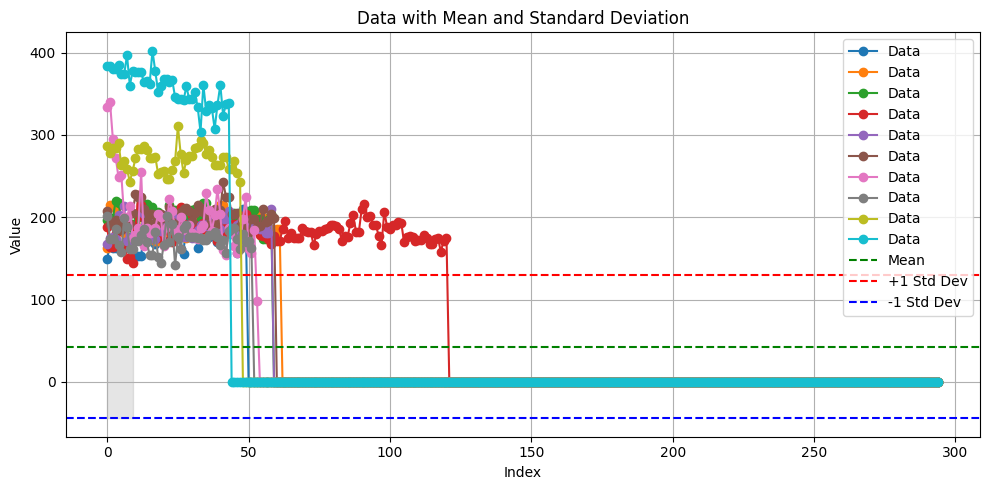

In [7]:
import matplotlib.pyplot as plt

# Calculate mean and standard deviation

data = X_train[:10, :295, 0]
#data[data == 0] = np.nan
mean = np.mean(data)
std_dev = np.std(data)

# Plotting
plt.figure(figsize=(10, 5))
plt.plot(data.T, marker='o', label='Data')
plt.axhline(mean, color='green', linestyle='--', label='Mean')
plt.axhline(mean + std_dev, color='red', linestyle='--', label='+1 Std Dev')
plt.axhline(mean - std_dev, color='blue', linestyle='--', label='-1 Std Dev')
plt.fill_between(range(len(data)), mean - std_dev, mean + std_dev, color='gray', alpha=0.2)

# Labels and legend
plt.title('Data with Mean and Standard Deviation')
plt.xlabel('Index')
plt.ylabel('Value')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


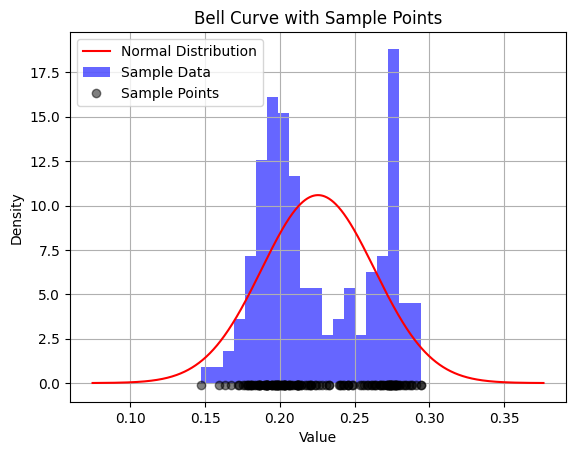

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

# Generate or use your sample data
data = y_test#targets_np #  np.random.normal(loc=0, scale=1, size=100)  # Replace this with your actual data

# Fit a normal distribution to the data
mean = np.mean(data)
std = np.std(data)

# Generate x values for the bell curve
x = np.linspace(mean - 4*std, mean + 4*std, 1000)
pdf = stats.norm.pdf(x, mean, std)

# Plot the bell curve
plt.plot(x, pdf, label='Normal Distribution', color='red')

# Plot the sample points as a histogram
plt.hist(data, bins=20, density=True, alpha=0.6, color='blue', label='Sample Data')

# Add the sample points as dots along the x-axis
y_min = -0.01 * max(pdf)
plt.plot(data, [y_min]*len(data), 'ko', alpha=0.5, label='Sample Points')

plt.title('Bell Curve with Sample Points')
plt.xlabel('Value')
plt.ylabel('Density')
plt.legend()
plt.grid(True)
plt.show()


#Model

##RNN, LSTM, GRU

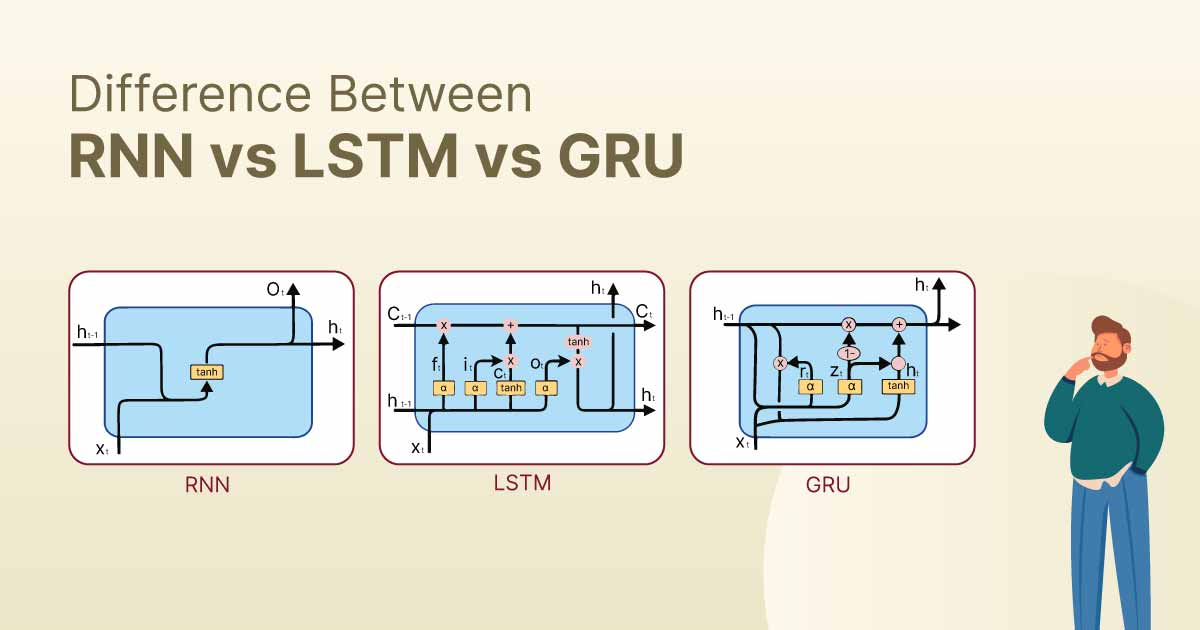

In [9]:
import tensorflow as tf
from xgboost import XGBRegressor
import numpy as np


import random
import os

# Set global seeds
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)


def correlation_loss(y_true, y_pred):
    x = y_true - tf.reduce_mean(y_true)
    y = y_pred - tf.reduce_mean(y_pred)
    corr = tf.reduce_sum(x * y) / (
        tf.sqrt(tf.reduce_sum(tf.square(x))) * tf.sqrt(tf.reduce_sum(tf.square(y))) + 1e-8)
    print("corr {}".format(corr))


    return 1 - corr  # 1 - correlation, so that lower = better

'''def correlation_loss(y_true, y_pred):
    pearson_r, _ = tf.contrib.metrics.streaming_pearson_correlation(y_pred, y_true)
    print("corr {}".format(pearson_r))
    return 1-pearson_r**2'''

mse_loss = tf.keras.losses.MeanSquaredError()

def combined_loss(y_true, y_pred):
    mse = mse_loss(y_true, y_pred)
    return mse + 0.1*correlation_loss(y_true, y_pred)

def single_head_attention(x):
    # Attention mechanism
    feature_dim = x.shape[-1]

    attention = tf.keras.layers.Dense(1, activation='tanh')(x)
    attention = tf.keras.layers.Flatten()(attention)
    attention = tf.keras.layers.Activation('softmax')(attention)
    attention = tf.keras.layers.RepeatVector(feature_dim)(attention)
    attention = tf.keras.layers.Permute([2, 1])(attention)

    # Apply attention to Bi-GRU outputs
    weighted = tf.keras.layers.Multiply()([x, attention])
    summed = tf.keras.layers.Lambda(lambda x: tf.reduce_sum(x, axis=1))(weighted)
    return summed

def multi_head_attention(x, num_heads = 8, head_dim = 32):
    multi_head_output = tf.keras.layers.MultiHeadAttention(
      num_heads=num_heads,         # You can choose 4, 8, etc.
      key_dim=head_dim           # Dimensionality of each head
    )(x, x, x)

    # (Optional) Add & Normalize (if you want Transformer-like architecture)
    x = tf.keras.layers.LayerNormalization(epsilon=1e-6)(x + multi_head_output)

    # Pooling or reduction
    summed = tf.keras.layers.GlobalAveragePooling1D()(x)
    return summed

def rnn_layer(model_type, node_n = 256, return_sequences= False):
    if model_type == 'RNN':
      return tf.keras.layers.SimpleRNN(
          node_n,
          return_sequences=return_sequences,  # Required for attention
          kernel_initializer=tf.keras.initializers.GlorotUniform(seed=SEED),
          recurrent_initializer=tf.keras.initializers.Orthogonal(seed=SEED),
          bias_initializer=tf.keras.initializers.Zeros()
      )
    elif model_type == 'LSTM':
      return tf.keras.layers.LSTM(
          node_n,
          return_sequences=return_sequences,  # Required for attention
          kernel_initializer=tf.keras.initializers.GlorotUniform(seed=SEED),
          recurrent_initializer=tf.keras.initializers.Orthogonal(seed=SEED),
          bias_initializer=tf.keras.initializers.Zeros()
      )
    elif model_type == 'GRU':
      return tf.keras.layers.GRU(
          node_n,
          return_sequences=return_sequences,  # Required for attention
          kernel_initializer=tf.keras.initializers.GlorotUniform(seed=SEED),
          recurrent_initializer=tf.keras.initializers.Orthogonal(seed=SEED),
          bias_initializer=tf.keras.initializers.Zeros()
      )


def build_model(model_type, attention=False, multi_head=0, bidirect=False):
  input_shape = (None, padded_features_np.shape[2])

  # Input
  inputs = tf.keras.Input(shape=input_shape)

  cell = rnn_layer(model_type, return_sequences = (attention or multi_head))

  if bidirect:
    x = tf.keras.layers.Bidirectional(cell)(inputs)
  else:
    x = cell(inputs)

  #x = tf.keras.layers.BatchNormalization()(x)
  #x = tf.keras.layers.Activation('relu')(x)


  if multi_head > 0:
    summed = multi_head_attention(x, num_heads = multi_head)
  elif attention:
    summed = single_head_attention(x)
  else:
    summed = x


  output = tf.keras.layers.Dense(
    1,
    kernel_initializer=tf.keras.initializers.GlorotUniform(seed=SEED),
    bias_initializer=tf.keras.initializers.Zeros()
  )(summed)

  # Model
  model = tf.keras.Model(inputs=inputs, outputs=output)


  print("Compile Model")
  model.compile(optimizer='adam', loss='mse', metrics=['mae'])
  #model.compile(optimizer='adam', loss=combined_loss, metrics=['mae'])

  return model

## (skip) Neural Ordinary Differential Equations (arXiv:1806.07366) and Neural Ordinary Integral Equations

In [ ]:
import tensorflow as tf
import tensorflow_probability as tfp
import numpy as np
import matplotlib.pyplot as plt

tf.keras.utils.set_random_seed(42)
tfd = tfp.distributions
ode = tfp.math.ode

# === Define ODE function (dx/dt = f(x, t)) ===
class ODEFunc(tf.keras.Model):
    def __init__(self):
        super().__init__()
        self.net = tf.keras.Sequential([
            tf.keras.layers.Dense(50, activation="tanh"),
            tf.keras.layers.Dense(1)
        ])

    def call(self, t, y):
        return self.net(y)  # f(y, t)

# === Generate synthetic data (true dynamics = dx/dt = -0.5x) ===
t = np.linspace(0, 10, 100, dtype=np.float32)
y0 = np.array([[2.0]], dtype=np.float32)

true_y = y0 * np.exp(-0.5 * t).reshape(-1, 1)  # analytic solution
noisy_y = true_y + 0.1 * np.random.randn(*true_y.shape)

# === Training setup ===
func = ODEFunc()
optimizer = tf.keras.optimizers.Adam(learning_rate=0.01)
loss_fn = tf.keras.losses.MeanSquaredError()

# ODE solver (Runge-Kutta)
solver = ode.DormandPrince(atol=1e-5, rtol=1e-5)

# === Training loop ===
for epoch in range(2000):
    with tf.GradientTape() as tape:
        # Integrate the learned dynamics
        results = solver.solve(
            ode_fn=func,
            initial_time=0.0,
            initial_state=y0,
            solution_times=t
        )
        pred_y = results.states  # (100, 1)
        loss = loss_fn(noisy_y, pred_y)

    grads = tape.gradient(loss, func.trainable_variables)
    optimizer.apply_gradients(zip(grads, func.trainable_variables))

    if epoch % 200 == 0:
        print(f"Epoch {epoch}, Loss {loss.numpy():.4f}")

# === Evaluate ===
results = solver.solve(
    ode_fn=func,
    initial_time=0.0,
    initial_state=y0,
    solution_times=t
)
pred_y = results.states.numpy()

# === Plot ===
plt.plot(t, noisy_y, "o", label="Noisy observations")
plt.plot(t, true_y, "g-", label="True trajectory")
plt.plot(t, pred_y, "r--", label="Neural ODE prediction")
plt.legend()
plt.show()


Instructions for updating:
back_prop=False is deprecated. Consider using tf.stop_gradient instead.
Instead of:
results = tf.while_loop(c, b, vars, back_prop=False)
Use:
results = tf.nest.map_structure(tf.stop_gradient, tf.while_loop(c, b, vars))


Epoch 0, Loss 3.4611
Epoch 200, Loss 0.0080


In [ ]:
from sklearn.preprocessing import RobustScaler, StandardScaler

# Assume you already have your training set padded_features_np
# Compute what the "summed" would look like (summing over axis=1 like in your model)
summed_train = padded_features_np.sum(axis=1)  # shape: (N_samples, 8)

scaler = RobustScaler()
scaler.fit(summed_train)

median = scaler.center_    # array of medians (shape: (8,))
iqr = scaler.scale_        # array of IQRs (shape: (8,))

median_const = tf.constant(median, dtype=tf.float32)
iqr_const = tf.constant(iqr, dtype=tf.float32)

'''scaler = StandardScaler()

# Fit the scaler on your training data
scaler.fit(summed_train)

# Extract mean and standard deviation
mean = scaler.mean_           # array of means (shape: (num_features,))
std = scaler.scale_           # array of standard deviations (shape: (num_features,))

# Convert to TensorFlow constants
mean_const = tf.constant(mean, dtype=tf.float32)
std_const = tf.constant(std, dtype=tf.float32)'''

def robust_scale(x):
    return (x - median_const) / (iqr_const + 1e-8)  # add epsilon to avoid div/0



In [ ]:
import tensorflow_probability as tfp

class RobustNormalization(tf.keras.layers.Layer):
    def build(self, input_shape):
        # Trainable variables or moving stats
        self.median = self.add_weight(
            shape=(input_shape[-1],), initializer="zeros", trainable=False)
        self.iqr = self.add_weight(
            shape=(input_shape[-1],), initializer="ones", trainable=False)

    def call(self, inputs, training=None):
        if training:
            median = tfp.stats.percentile(inputs, 50.0, axis=0)
            q1 = tfp.stats.percentile(inputs, 25.0, axis=0)
            q3 = tfp.stats.percentile(inputs, 75.0, axis=0)
            iqr = q3 - q1

            # Update moving stats (simplified, like BatchNorm EMA update)
            self.median.assign(median)
            self.iqr.assign(iqr)

        return (inputs - self.median) / (self.iqr + 1e-6)


In [ ]:
import tensorflow as tf

# Input layer
input = tf.keras.layers.Input(shape=(None, padded_features_np.shape[2]))  # (batch_size, time_steps, features)

# Sum over axis 1 (i.e., summing across the time dimension)
summed = tf.keras.layers.Lambda(lambda x: tf.reduce_sum(x, axis=1))(input)  # Shape: (batch_size, 8)

# Apply RobustNormalization
normalized = tf.keras.layers.Lambda(robust_scale)(summed)
#normalized = RobustNormalization()(summed)

# Custom operation: (f1 - f2 - f3) / f4
'''outputs = tf.keras.layers.Lambda(
    lambda x: tf.expand_dims(tf.math.divide_no_nan(x[:, 0] - x[:, 1] - x[:, 2], x[:, 3]), axis=-1)
)(summed)'''

dropout_rate = 0.5
# Dense network instead of manual division
#x = tf.keras.layers.BatchNormalization()(summed)
'''x = tf.keras.layers.Dense(256, activation="relu")(x)
x = tf.keras.layers.Dropout(dropout_rate)(x)
x = tf.keras.layers.Dense(128, activation="relu")(x)
x = tf.keras.layers.Dropout(dropout_rate)(x)'''
x = tf.keras.layers.Dense(64, activation="relu")(normalized)
#x = tf.keras.layers.Dropout(dropout_rate)(x)
x = tf.keras.layers.Dense(64, activation="relu")(x)
#x = tf.keras.layers.Dropout(dropout_rate)(x)
x = tf.keras.layers.Dense(32, activation="relu")(x)
#x = tf.keras.layers.Dropout(dropout_rate)(x)
outputs = tf.keras.layers.Dense(1)(x)

# Create model
model = tf.keras.Model(inputs=input, outputs=outputs)

# Compile (for example)
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4), loss='mse', metrics=['mae'])

# Model summary
model.summary()

Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, None, 4)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_10 (Lambda)              │ (None, 4)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_11 (Lambda)              │ (None, 4)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 64)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,593 (25.75 KB)

 Trainable params: 6,593 (25.75 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
import tensorflow as tf

# Custom RNN cell that accumulates inputs
class AccumulatorCell(tf.keras.layers.Layer):
    def __init__(self, units, trainable_transform=False, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.trainable_transform = trainable_transform

    @property
    def state_size(self):
        return self.units

    @property
    def output_size(self):
        return self.units

    def build(self, input_shape):
        if self.trainable_transform:
            # Learnable weight matrix to transform input before accumulation
            self.W = self.add_weight(
                shape=(input_shape[-1], self.units),
                initializer="glorot_uniform",
                trainable=True
            )
        else:
            self.W = None
        super().build(input_shape)

    def call(self, inputs, states):
        prev_h = states[0]
        if self.W is not None:
            inputs = tf.matmul(inputs, self.W)
        new_h = prev_h + inputs
        return new_h, [new_h]

# Example usage
units = 4

input = tf.keras.layers.Input(shape=(None, padded_features_np.shape[2]))
x = tf.keras.layers.RNN(AccumulatorCell(units))(input)
#x = tf.keras.layers.Dense(4, use_bias=False)(x)
#x = tf.keras.layers.BatchNormalization()(x)
#x = tf.keras.layers.Activation('relu')(x)

outputs = tf.keras.layers.Lambda(
    lambda x: tf.expand_dims(tf.math.divide_no_nan(x[:, 0] - x[:, 1] - x[:, 2], x[:, 3]), axis=-1)
)(x)

'''x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.Dense(64, activation="relu")(x)
x = tf.keras.layers.Dense(64, activation="relu")(x)
x = tf.keras.layers.Dense(32, activation="relu")(x)

outputs = tf.keras.layers.Dense(1)(x)'''

# Create model
model = tf.keras.Model(inputs=input, outputs=outputs)

# Compile (for example)
model.compile(optimizer='adam', loss='mse', metrics=['mae'])

# Model summary
model.summary()


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, None, 4)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rnn_1 (RNN)                     │ (None, 4)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_5 (Lambda)               │ (None, 1)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

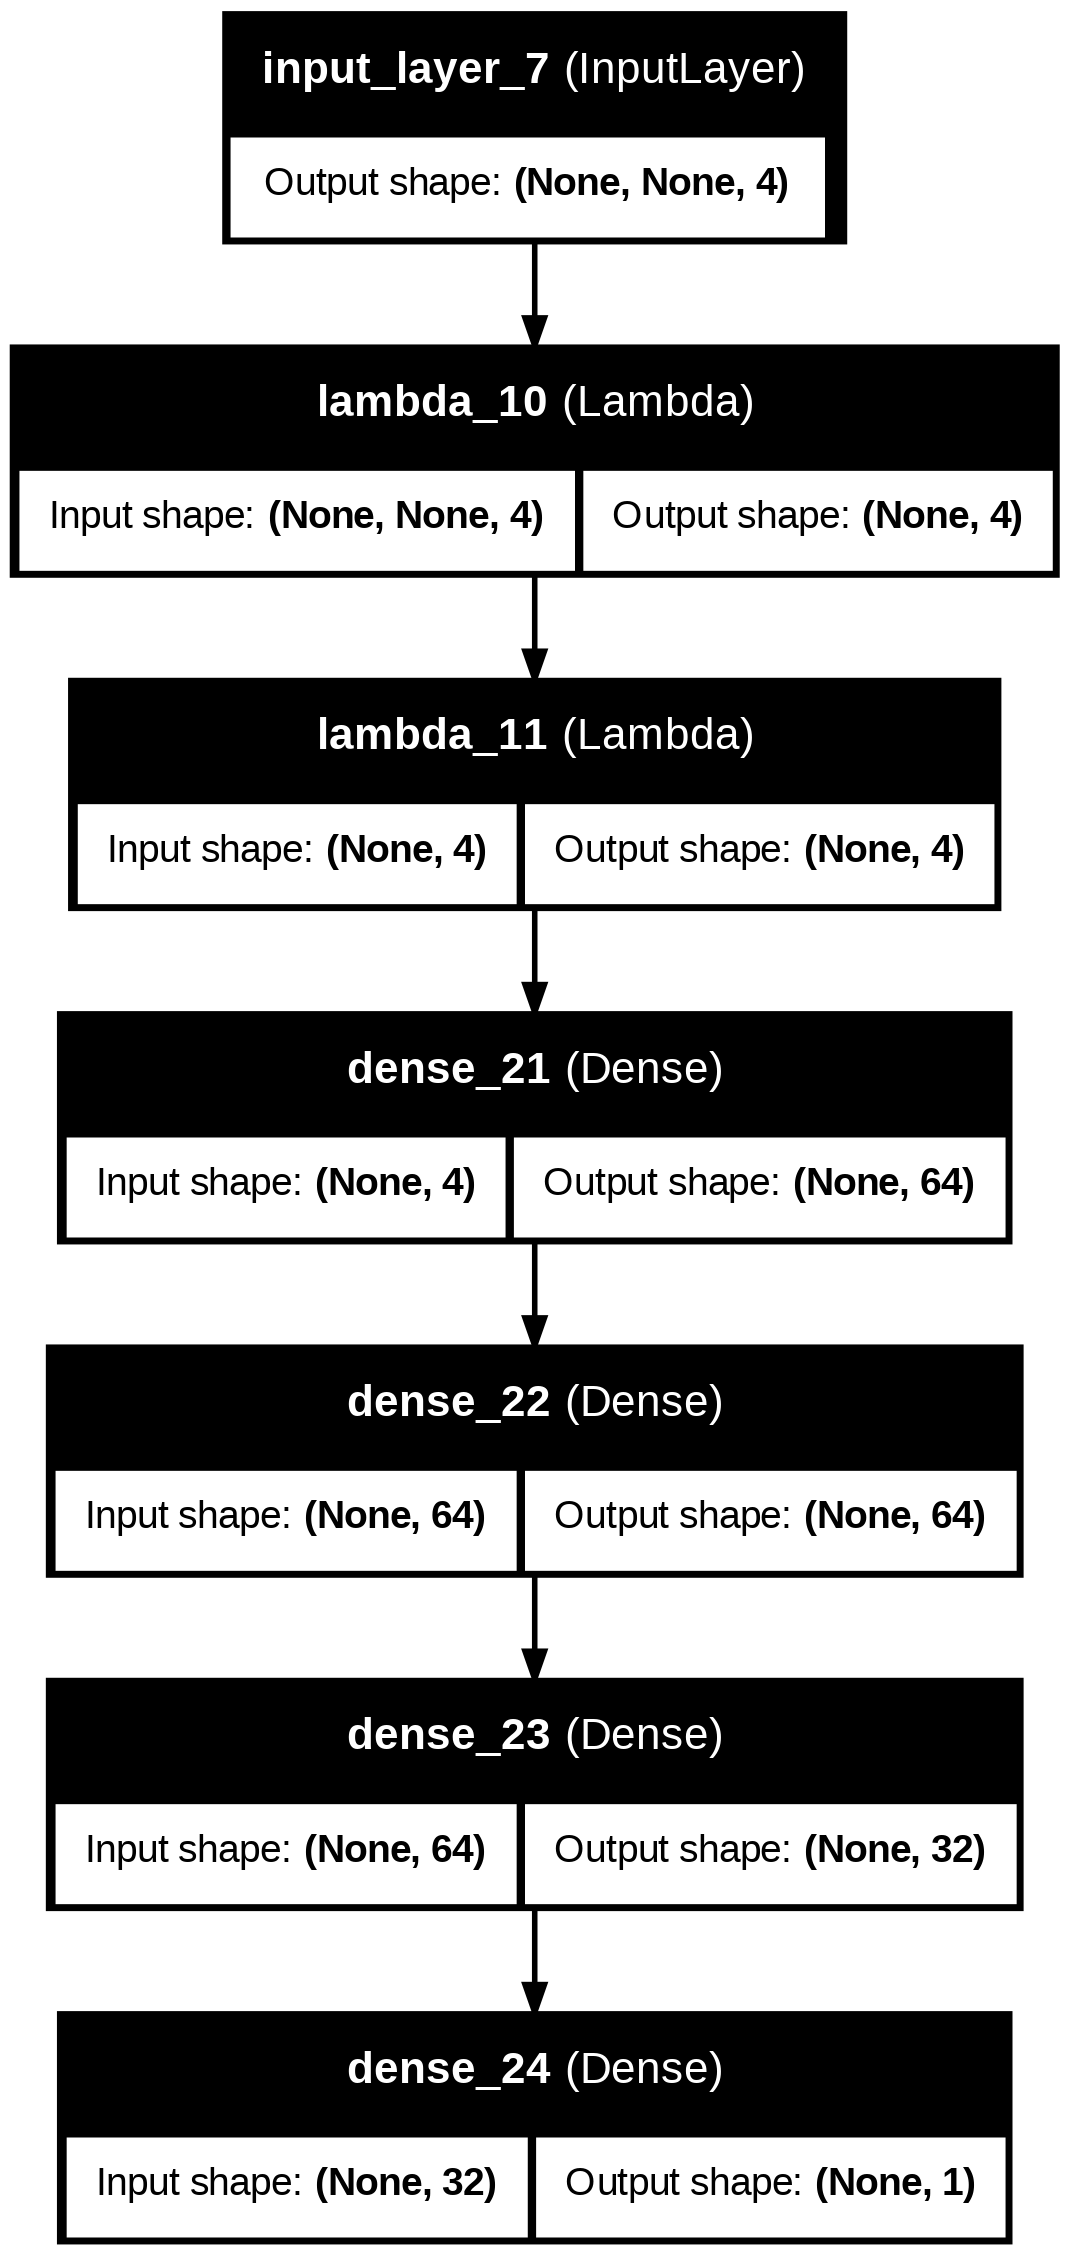

In [ ]:
from tensorflow.keras.utils import plot_model

plot_model(model, to_file='model.png', show_shapes=True, show_layer_names=True)

#Train

## (skip) Regresion

In [ ]:
#tensorboard_callback = tf.keras.callbacks.TensorBoard(log_dir="./logs")
from tensorflow.keras.callbacks import EarlyStopping
#For XGBoost
from sklearn.metrics import mean_squared_error, mean_absolute_error


early_stopping = EarlyStopping(
    monitor='val_loss',     # What metric to monitor
    patience=5,             # Number of epochs with no improvement after which training will be stopped
    restore_best_weights=True  # Restores model weights from the epoch with the best value of the monitored quantity
)

#tf.keras.backend.clear_session()

batch_s = 8
epochs_n = 50

size = y_train.shape[0]
print(size)
training_sizes = [round(size*0.1), round(size*0.2), round(size*0.3), round(size*0.4), round(size*0.5), round(size*0.6), round(size*0.7), round(size*0.8), round(size*0.9), size]

'''xgboost_mae  = []
model = build_model('XGBoost')
for size in training_sizes:
  history = model.fit(X_train[:size], y_train[:size])

  y_pred = model.predict(X_test)

  # Evaluate
  mse = mean_absolute_error(y_test, y_pred)
  print(f"Test MSE: {mse}")
  xgboost_mae.append(mse)'''


'''gru_mae  = []
model = build_model('GRU')
print(type(model))
for size in training_sizes:
  history = model.fit(X_train[:size], y_train[:size], epochs=epochs_n, batch_size=batch_s, validation_data=(X_test, y_test), callbacks=[early_stopping])
  gru_mae.append(model.evaluate(X_test, y_test)[1])'''


'''lstm_mae  = []
model = build_model('LSTM')
for size in training_sizes:
  history = model.fit(X_train[:size], y_train[:size], epochs=epochs_n, batch_size=batch_s, validation_data=(X_test, y_test), callbacks=[early_stopping])
  lstm_mae.append(model.evaluate(X_test, y_test)[1])'''


bigru_mae  = []
#model = build_model('LSTM', attention=True, multi_head=0, bidirect=False)
for size in training_sizes:
  history = model.fit(X_train[:size], y_train[:size], epochs=epochs_n, batch_size=batch_s, validation_data=(X_test, y_test), callbacks=[early_stopping])
  bigru_mae.append(model.evaluate(X_test, y_test)[1])

605
Epoch 1/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 155ms/step - loss: 0.0241 - mae: 0.1366 - val_loss: 4.3555 - val_mae: 0.4832
Epoch 2/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0039 - mae: 0.0431 - val_loss: 2.0903 - val_mae: 0.3158
Epoch 3/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0036 - mae: 0.0449 - val_loss: 0.9702 - val_mae: 0.2074
Epoch 4/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0038 - mae: 0.0497 - val_loss: 0.9164 - val_mae: 0.2004
Epoch 5/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0028 - mae: 0.0426 - val_loss: 0.4778 - val_mae: 0.1452
Epoch 6/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0017 - mae: 0.0334 - val_loss: 0.3167 - val_mae: 0.1312
Epoch 7/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0017 - mae: 0.0321 - val_loss: 0.1944 - val_mae: 0.1056
Epoch 8/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0014 - mae: 0.0280 - val_loss: 0.2130 - val_mae: 0.1070
Epoch 9/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0012 - mae: 0.02

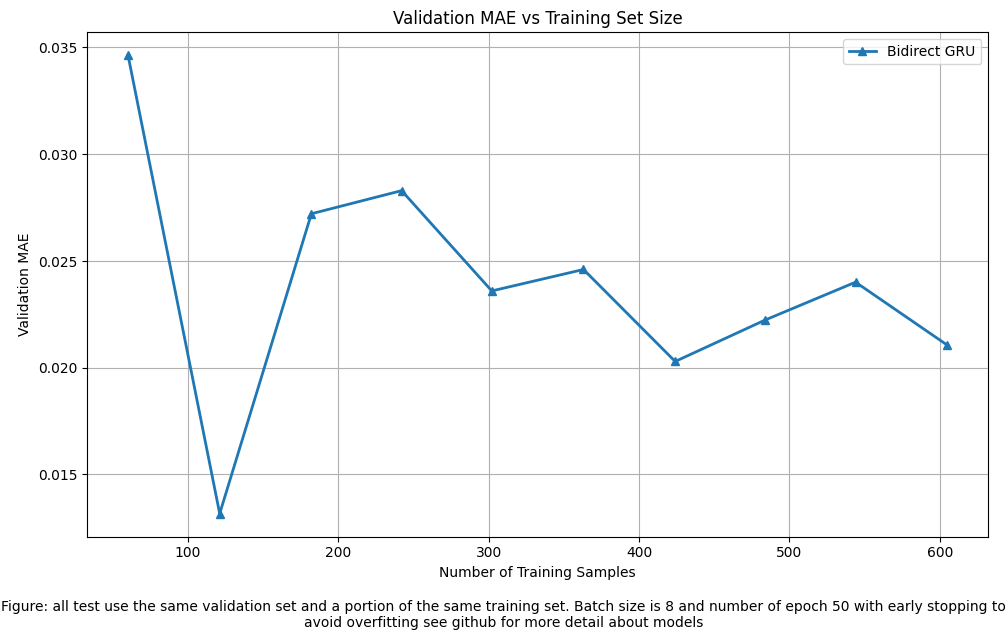

In [ ]:
import matplotlib.pyplot as plt

# Example data (replace with your actual values)

# Plotting
plt.figure(figsize=(10, 6))
#plt.plot(training_sizes, xgboost_mae, marker='o', label='LSTM', linewidth=2)
#plt.plot(training_sizes, lstm_mae, marker='o', label='LSTM', linewidth=2)
#plt.plot(training_sizes, gru_mae, marker='s', label='GRU', linewidth=2)
plt.plot(training_sizes, bigru_mae, marker='^', label='Bidirect GRU', linewidth=2)

# Labels and title
plt.xlabel('Number of Training Samples')
plt.ylabel('Validation MAE')
plt.title('Validation MAE vs Training Set Size')
plt.legend()
plt.grid(True)


plt.figtext(0.5, -0.05,
            'Figure: all test use the same validation set and a portion of the same training set. Batch size is 8 and number of epoch 50 with early stopping to avoid overfitting see github for more detail about models',
            wrap=True, horizontalalignment='center', fontsize=10)


plt.tight_layout()

# Show plot
plt.show()


## Simple Training

In [10]:
#tensorboard_callback = tf.keras.callbacks.TensorBoard(log_dir="./logs")
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor='val_loss',     # What metric to monitor
    patience=5,             # Number of epochs with no improvement after which training will be stopped
    restore_best_weights=True  # Restores model weights from the epoch with the best value of the monitored quantity
)

model = build_model('LSTM', attention=True, multi_head=0, bidirect=False)

model.summary()

#history = model.fit(X_train, y_train, epochs=75, batch_size=4, validation_data=(X_test, y_test), callbacks=[tensorboard_callback])
history = model.fit(X_train, y_train, epochs=200, batch_size=8, validation_data=(X_test, y_test), callbacks=[early_stopping])

#history = model.fit(X_train, y_train)

Compile Model


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, None, 4)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, None, 256) │    267,264 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, None, 1)   │        257 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, None)      │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, None)      │          0 │ flatten[0][0]     │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_vector       │ (None, 256, None) │          0 │ activation[0][0]  │
│ (RepeatVector)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ permute (Permute)   │ (None, None, 256) │          0 │ repeat_vector[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, None, 256) │          0 │ lstm[0][0],       │
│                     │                   │            │ permute[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda (Lambda)     │ (None, 256)       │          0 │ multiply[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1)         │        257 │ lambda[0][0]      │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 267,778 (1.02 MB)

 Trainable params: 267,778 (1.02 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
76/76 ━━━━━━━━━━━━━━━━━━━━ 10s 34ms/step - loss: 0.0101 - mae: 0.0691 - val_loss: 0.0051 - val_mae: 0.0429
Epoch 2/200
76/76 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0034 - mae: 0.0332 - val_loss: 8.2901e-04 - val_mae: 0.0236
Epoch 3/200
76/76 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 8.5337e-04 - mae: 0.0222 - val_loss: 4.5973e-04 - val_mae: 0.0164
Epoch 4/200
76/76 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 3.7537e-04 - mae: 0.0155 - val_loss: 3.5574e-04 - val_mae: 0.0141
Epoch 5/200
76/76 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 2.9139e-04 - mae: 0.0135 - val_loss: 2.3642e-04 - val_mae: 0.0114
Epoch 6/200
76/76 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 2.5630e-04 - mae: 0.0129 - val_loss: 4.3214e-04 - val_mae: 0.0156
Epoch 7/200
76/76 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 2.7254e-04 - mae: 0.0127 - val_loss: 2.2817e-04 - val_mae: 0.0116
Epoch 8/200
76/76 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - loss: 1.9802e-04 - mae: 0.0114 - val_loss: 2.2939e-04 - val_mae: 0.0114
Epo

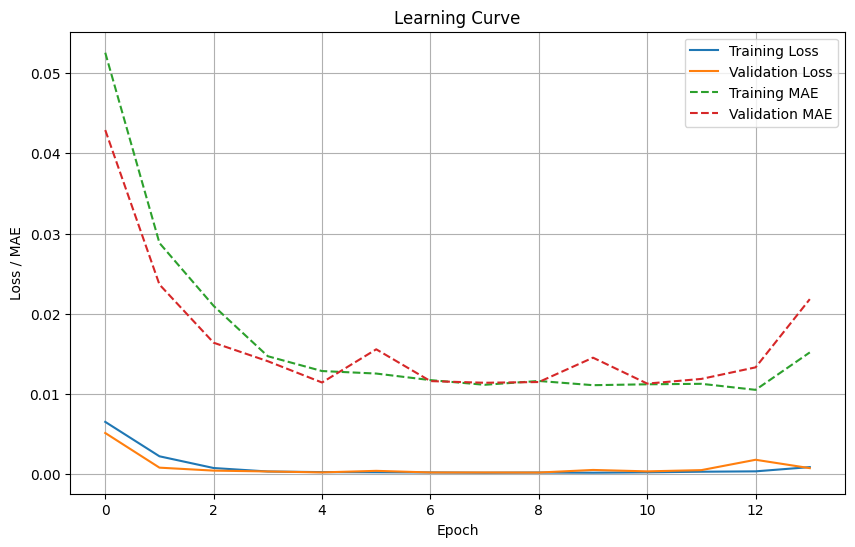

In [11]:
import matplotlib.pyplot as plt

# Plot training & validation loss
plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

# Optional: plot additional metrics like MAE
if 'mae' in history.history:
    plt.plot(history.history['mae'], label='Training MAE', linestyle='--')
    plt.plot(history.history['val_mae'], label='Validation MAE', linestyle='--')

plt.title('Learning Curve')
plt.xlabel('Epoch')
plt.ylabel('Loss / MAE')
plt.legend()
plt.grid(True)
plt.show()


#Evaluate

## (skip) Arithmetic method

In [ ]:
import numpy as np

# Assuming X_test has shape (117, 307, 4)
X_test_summed = np.sum(padded_features_np, axis=1)  # Sum along the 307 timestep dimension

#print(X_test_summed)

f1 = X_test_summed[:, 0]  # Feature 1
f2 = X_test_summed[:, 1]  # Feature 2
f3 = X_test_summed[:, 2]  # Feature 3
f4 = X_test_summed[:, 3]  # Feature 4

# Compute the desired expression
#X_custom = (f1 - f2 - f3) / (f4 + 1e-8)
numerator = f1 - f2 - f3
X_custom = np.where(f4 == 0, 0, numerator / f4)

y_pred = X_custom

#For XGBoost
from sklearn.metrics import mean_squared_error, mean_absolute_error


# Evaluate
mse = mean_absolute_error(targets_np, y_pred)
print(f"Test MAE: {mse}")

print(combined_loss(targets_np, y_pred.flatten()))

print(f1.shape, f2.shape, f3.shape, f4.shape)


/tmp/ipython-input-2924705478.py:16: RuntimeWarning: divide by zero encountered in divide
  X_custom = np.where(f4 == 0, 0, numerator / f4)


Test MAE: 0.004865326453000307
corr 0.8236642479896545
tf.Tensor(0.018247114, shape=(), dtype=float32)
(757,) (757,) (757,) (757,)


In [ ]:
# Plot
plt.figure(figsize=(10, 6))
plt.plot(f1, label="Feature 1")
plt.plot(f2, label="Feature 2", linestyle='--')
plt.plot(f3, label="Feature 3")
plt.plot(f4, label="Feature 4", linestyle='--')
#plt.plot(y_pred, label="Prediction")
plt.xlabel("Sample index")
plt.ylabel("Summed feature value")
plt.title("Summed Features Across Samples")
#plt.yscale("log")
plt.legend()
plt.show()

NameError: name 'plt' is not defined

In [ ]:
data1 = f1
mean1 = np.mean(data1)
std1 = np.std(data1)

# Generate x values for the bell curve
x1 = np.linspace(mean1 - 4*std, mean1 + 4*std, 1000)
pdf = stats.norm.pdf(x1, mean1, std1)


# Create 2x2 grid of plots
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

y_min = -0.01 * max(pdf)
axes[0, 0].plot(x1, pdf, color='red', label='Normal Distribution: mean {}, std {}'.format(mean1,std1))
axes[0, 0].hist(data1, bins=20, density=True, alpha=0.6, color='blue')
axes[0, 0].plot(data1, [y_min]*len(data1), 'ko', alpha=0.5, label='Sample Points')
axes[0, 0].set_title("Bell Curve with Sample Points f1")
axes[0, 0].legend()
axes[0, 0].grid(True)


data = f2
mean = np.mean(data)
std = np.std(data)

# Generate x values for the bell curve
x = np.linspace(mean - 4*std, mean + 4*std, 1000)
pdf = stats.norm.pdf(x, mean, std)

y_min = -0.01 * max(pdf)
axes[0, 1].plot(x, pdf, color='red', label='Normal Distribution: mean {}, std {}'.format(mean,std))
axes[0, 1].hist(data, bins=20, density=True, alpha=0.6, color='blue')
axes[0, 1].plot(data, [y_min]*len(data), 'ko', alpha=0.5, label='Sample Points')
axes[0, 1].set_title("Bell Curve with Sample Points f2")
axes[0, 1].legend()
axes[0, 1].grid(True)

data = f3
mean = np.mean(data)
std = np.std(data)

# Generate x values for the bell curve
x = np.linspace(mean - 4*std, mean + 4*std, 1000)
pdf = stats.norm.pdf(x, mean, std)

y_min = -0.01 * max(pdf)
axes[1, 0].plot(x, pdf, color='red', label='Normal Distribution: mean {}, std {}'.format(mean,std))
axes[1, 0].hist(data, bins=20, density=True, alpha=0.6, color='blue')
axes[1, 0].plot(data, [y_min]*len(data), 'ko', alpha=0.5, label='Sample Points')
axes[1, 0].set_title("Bell Curve with Sample Points f3")
axes[1, 0].legend()
axes[1, 0].grid(True)

data = f4
mean = np.mean(data)
std = np.std(data)

# Generate x values for the bell curve
x = np.linspace(mean - 4*std, mean + 4*std, 1000)
pdf = stats.norm.pdf(x, mean, std)

y_min = -0.01 * max(pdf)
axes[1, 1].plot(x, pdf, color='red', label='Normal Distribution: mean {}, std {}'.format(mean,std))
axes[1, 1].hist(data, bins=20, density=True, alpha=0.6, color='blue')
axes[1, 1].plot(data, [y_min]*len(data), 'ko', alpha=0.5, label='Sample Points')
axes[1, 1].set_title("Bell Curve with Sample Points f4")
axes[1, 1].legend()
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()

NameError: name 'std' is not defined

## (skip) Data generation

In [ ]:
import csv
import random

# Number of rows you want in the CSV
num_rows = 100000

data1 = f1
mean1 = np.mean(data1)
std1 = np.std(data1)

data2 = f2
mean2 = np.mean(data2)
std2 = np.std(data2)

data3 = f3
mean3 = np.mean(data3)
std3 = np.std(data3)

data4 = f4
mean4 = np.mean(data4)
std4 = np.std(data4)

os.makedirs(testpath, exist_ok=True)  # make sure folder exists
filename = os.path.join(testpath, "random_data.csv")

# Open a CSV file to write
with open(filename, "w", newline="") as csvfile:
    writer = csv.writer(csvfile)

    # Write header
    writer.writerow(["power", "crr", "acc","air" ,"cda"])

    # Generate rows
    for _ in range(num_rows):
        col1 = random.gauss(mean1, std1)
        col2 = random.gauss(mean2, std2)
        col3 = random.gauss(mean3, std3)
        col4 = random.gauss(mean4, std4)
        cda = (col1 - col2 - col3)/col4
        writer.writerow([col1, col2, col3, col4, cda])

print("CSV file 'random_data.csv' generated successfully.")


CSV file 'random_data.csv' generated successfully.


In [ ]:
import tensorflow as tf

input = tf.keras.layers.Input(shape=(4,))

#x = tf.keras.layers.LayerNormalization()(input)
x = tf.keras.layers.Dense(16, activation="relu")(input)
#x = tf.keras.layers.Dense(64, activation="relu")(x)
x = tf.keras.layers.Dense(8, activation="relu")(x)

outputs = tf.keras.layers.Dense(1)(x)

# Create model
model = tf.keras.Model(inputs=input, outputs=outputs)

# Compile (for example)
#model.compile(optimizer='adam', loss='mse', metrics=['mae'])
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4), loss='mse', metrics=['mae'])

model.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 4)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225 (900.00 B)

 Trainable params: 225 (900.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import RobustScaler

X = np.stack([f1, f2, f3, f4], axis=1)

# Path to CSV
'''filename = testpath + "random_data.csv"

# Load CSV into a pandas DataFrame
df = pd.read_csv(filename)

# Separate features (X) and target (y)
X = df[["power", "crr", "acc","air"]]  # input features
y = df["cda"]  # target column'''

# Normalize inputs and outputs with RobustScaler (less sensitive to outliers)
x_scaler = RobustScaler()
y_scaler = RobustScaler()

X = x_scaler.fit_transform(X)
y = targets_np
y = y_scaler.fit_transform(y.reshape(-1, 1))

# Split into train and validation sets (80% train, 20% validation for example)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training set size:", X_train.shape)
print("Validation set size:", X_test.shape)


Training set size: (605, 4)
Validation set size: (152, 4)


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor='val_loss',     # What metric to monitor
    patience=5,             # Number of epochs with no improvement after which training will be stopped
    restore_best_weights=True  # Restores model weights from the epoch with the best value of the monitored quantity
)

history = model.fit(X_train, y_train, epochs=1000, batch_size=32, validation_data=(X_test, y_test), callbacks=[early_stopping])

Epoch 1/2000
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 63ms/step - loss: 1.2357 - mae: 0.6126 - val_loss: 1.1501 - val_mae: 0.5983
Epoch 2/2000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 1.1922 - mae: 0.6020 - val_loss: 1.1105 - val_mae: 0.5880
Epoch 3/2000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 1.1523 - mae: 0.5920 - val_loss: 1.0729 - val_mae: 0.5780
Epoch 4/2000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 1.1142 - mae: 0.5824 - val_loss: 1.0371 - val_mae: 0.5681
Epoch 5/2000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 1.0777 - mae: 0.5735 - val_loss: 1.0029 - val_mae: 0.5590
Epoch 6/2000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 1.0429 - mae: 0.5650 - val_loss: 0.9704 - val_mae: 0.5508
Epoch 7/2000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 1.0096 - mae: 0.5569 - val_loss: 0.9391 - val_mae: 0.5436
Epoch 8/2000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.9777 - mae: 0.5494 - val_loss: 0.9089 - val_mae: 0.5372
Epoch 9/2000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/ste

In [ ]:
# Evaluate the model
test_loss = model.evaluate(X_test, y_test, verbose=0)
print("Test Loss (normalized scale):", test_loss)

# Predictions in original scale
preds = model.predict(X_test)
y_pred = y_scaler.inverse_transform(preds)
y_test = y_scaler.inverse_transform(y_test)

# Compare a few predictions
for i in range(5):
    print(f"True: {y_test[i][0]:.3f}, Pred: {y_pred[i][0]:.3f}")

Test Loss (normalized scale): [0.002279179636389017, 0.035337984561920166]
1/5 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
True: 0.181, Pred: 0.175
True: 0.275, Pred: 0.278
True: 0.192, Pred: 0.193
True: 0.240, Pred: 0.240
True: 0.245, Pred: 0.242


In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
from sklearn.preprocessing import RobustScaler
from tensorflow.keras.callbacks import EarlyStopping

# Generate synthetic training data
N = 10000
x = np.random.randn(N, 4) * 5
x[:, 3] += 1e-3  # avoid division by zero
y = (x[:, 0] - x[:, 1] - x[:, 2]) / x[:, 3]

# Clip extreme values to avoid huge outliers
y = np.clip(y, -50, 50)
y = y.reshape(-1, 1)

# Split train/test
train_x, test_x = x[:8000], x[8000:]
train_y, test_y = y[:8000], y[8000:]

# Normalize inputs and outputs with RobustScaler (less sensitive to outliers)
x_scaler = RobustScaler()
y_scaler = RobustScaler()

train_x = x_scaler.fit_transform(train_x)
test_x = x_scaler.transform(test_x)

train_y = y_scaler.fit_transform(train_y)
test_y = y_scaler.transform(test_y)

# Define the model
model = keras.Sequential([
    layers.Dense(64, activation='relu', input_shape=(4,)),
    layers.Dense(64, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(1)
])

# Compile the model
model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-4), loss='mse', metrics=['mae'])

# Early

early_stopping = EarlyStopping(
    monitor='val_loss',     # What metric to monitor
    patience=5,             # Number of epochs with no improvement after which training will be stopped
    restore_best_weights=True  # Restores model weights from the epoch with the best value of the monitored quantity
)

# Train the model
history = model.fit(train_x, train_y, epochs=500, batch_size=128, verbose=1, validation_split=0.1, callbacks=[early_stopping])

# Evaluate the model
test_loss = model.evaluate(test_x, test_y, verbose=0)
print("Test Loss (normalized scale):", test_loss)

# Predictions in original scale
preds = model.predict(test_x)
preds = y_scaler.inverse_transform(preds)
true_y = y_scaler.inverse_transform(test_y)

# Compare a few predictions
for i in range(5):
    print(f"True: {true_y[i][0]:.3f}, Pred: {preds[i][0]:.3f}")




Epoch 1/500


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


57/57 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 8.3267 - mae: 1.3463 - val_loss: 10.1051 - val_mae: 1.4973
Epoch 2/500
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 8.6949 - mae: 1.3507 - val_loss: 10.0858 - val_mae: 1.4858
Epoch 3/500
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 8.8659 - mae: 1.3683 - val_loss: 10.0630 - val_mae: 1.4699
Epoch 4/500
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 8.9265 - mae: 1.3467 - val_loss: 10.0320 - val_mae: 1.4499
Epoch 5/500
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 8.8013 - mae: 1.3352 - val_loss: 9.9947 - val_mae: 1.4256
Epoch 6/500
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 8.6878 - mae: 1.2920 - val_loss: 9.9470 - val_mae: 1.3984
Epoch 7/500
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 8.5442 - mae: 1.2713 - val_loss: 9.8846 - val_mae: 1.3680
Epoch 8/500
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 8.4660 - mae: 1.2253 - val_loss: 9.8189 - val_mae: 1.3386
Epoch 9/500
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 8.7142 - mae:

##ML Method

In [12]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

print(X_test.shape)
y_pred = model.predict(X_test)


print(y_pred.shape)
print(y_test.shape)

# Evaluate
mse = mean_absolute_error(y_test, y_pred)
print(f"Test MAE: {mse}")

print(combined_loss(y_test, y_pred.flatten()))

(152, 309, 4)
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
(152, 1)
(152,)
Test MAE: 0.011498174630105495
corr 0.9327569007873535
tf.Tensor(0.006943519, shape=(), dtype=float32)


In [13]:
model.evaluate(X_test, y_test)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 2.1881e-04 - mae: 0.0116


[0.00021920923609286547, 0.01149817369878292]

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
(605, 1)
(605,)
Correlation between feature 0 and 1: 0.95


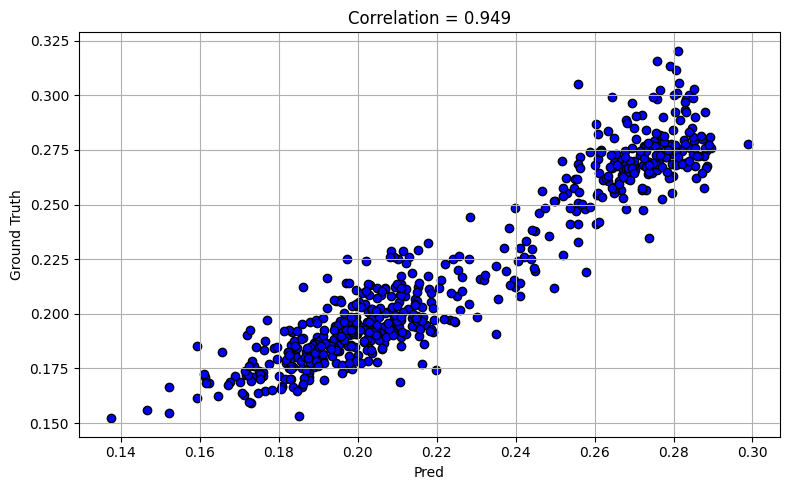

In [14]:
from scipy.stats import pearsonr

y = model.predict(X_train)

print(y.shape)
print(y_train.shape)

x = y.flatten()
y = y_train
corr, _ = pearsonr(x, y)

print(f"Correlation between feature 0 and 1: {corr:.2f}")


# Plot
plt.figure(figsize=(8, 5))
plt.scatter(y, x, color='blue', edgecolor='k')
plt.title(f"Correlation = {corr:.3f}")
plt.xlabel("Pred")
plt.ylabel("Ground Truth")
#plt.xlim(-200, 200)
#plt.ylim(26.705, 26.715)
plt.grid(True)
plt.tight_layout()
plt.show()

(152,)
(152,)
Correlation between feature 0 and 1: 0.93


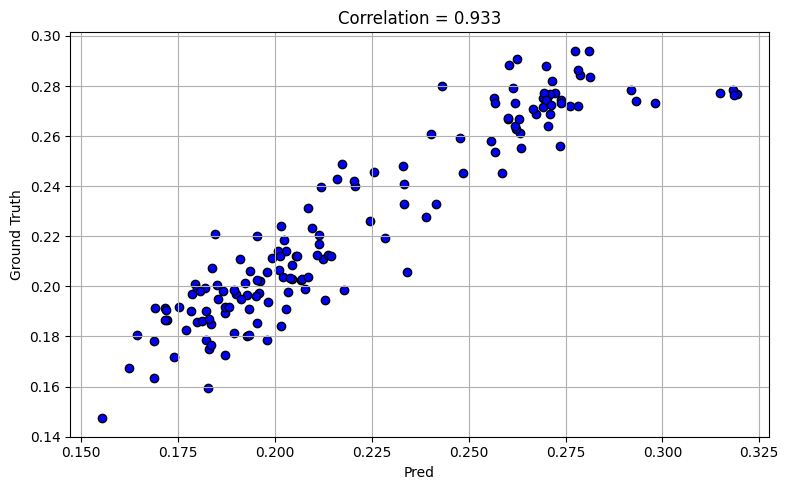

In [15]:
from scipy.stats import pearsonr


ground_truth = y_test
pred = y_pred.flatten()
print(ground_truth.shape)
print(pred.shape)

corr, _ = pearsonr(pred, ground_truth)
print(f"Correlation between feature 0 and 1: {corr:.2f}")


# Plot
plt.figure(figsize=(8, 5))
plt.scatter(pred, ground_truth, color='blue', edgecolor='k')
plt.title(f"Correlation = {corr:.3f}")
plt.xlabel("Pred")
plt.ylabel("Ground Truth")
#plt.xlim(0.22, 0.3)
#plt.ylim(-5, 5)
plt.grid(True)
plt.tight_layout()
plt.show()

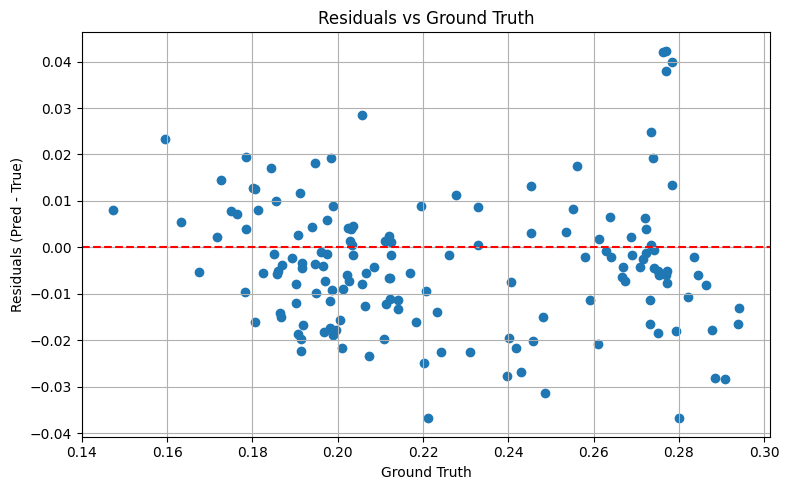

In [16]:
import matplotlib.pyplot as plt

# y_pred and y_true should be numpy arrays
residuals = pred - ground_truth

plt.figure(figsize=(8, 5))
plt.scatter(ground_truth, residuals)#, alpha=0.6)
plt.axhline(0, color='red', linestyle='--')
#plt.ylim(-0.02, 0.02)
plt.title("Residuals vs Ground Truth")
plt.xlabel("Ground Truth")
plt.ylabel("Residuals (Pred - True)")
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
%load_ext tensorboard

In [ ]:
%tensorboard --logdir=./logs

###Blind Test

In [17]:
print(X_blind_test.shape)

y = model.predict(X_blind_test)

print(y.shape)
print(y_train.shape)

for filename in os.listdir(os.path.join(testpath,test_name)):
    if filename.endswith('.csv') and filename.startswith('tmp-sum_'):
      print(f'load test file: {filename}')
      df_test_target = pd.read_csv(os.path.join(testpath,test_name, filename), header=None)

df_test_target[6] = y

print(df_test_target)

(6, 309, 4)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
(6, 1)
(605,)
load test file: tmp-sum___=MG2025-1_Mon Jul 28 031316 2025.csv
   0          1     2     3     4     5         6
0  0       DT/    486   629   688   833  0.256849
1  1  Test #2/    904  1046  1094  1236  0.293798
2  2  Test #3/   1306  1448  1495  1638  0.291593
3  3     Disc/   1876  2019  2071  2212  0.283176
4  4  Test #5/   2292  2437  2497  2639  0.254632
5  5  Test #6/   2721  2867  2921  3062  0.245690


In [ ]:
print(X_blind_test.shape)

y = model.predict(X_blind_test)

print(y.shape)
print(y_train.shape)

for filename in os.listdir(os.path.join(testpath,test_name)):
    if filename.endswith('.csv') and filename.startswith('tmp-sum_'):
      print(f'load test file: {filename}')
      df_test_target = pd.read_csv(os.path.join(testpath,test_name, filename), header=None)

df_test_target[6] = y

print(df_test_target)

#df_test_target.to_csv(os.path.join(testpath,test_name, f'pred-{filename}'), index=False)


(6, 309, 4)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 307ms/step
(6, 1)
(605,)
load test file: tmp-sum___=MG2025-1_Mon Jul 28 031316 2025.csv
   0          1     2     3     4     5         6
0  0       DT/    486   629   688   833  0.249837
1  1  Test #2/    904  1046  1094  1236  0.251057
2  2  Test #3/   1306  1448  1495  1638  0.255414
3  3     Disc/   1876  2019  2071  2212  0.244159
4  4  Test #5/   2292  2437  2497  2639  0.245711
5  5  Test #6/   2721  2867  2921  3062  0.243616


#Result

\begin{table}[h!]
\centering
\begin{tabular}{ll|ccc|ccc}
\toprule
& & \multicolumn{3}{c|}{\textbf{Unidirectional}} & \multicolumn{3}{c}{\textbf{Bidirectional}} \\
\textbf{Attention} &  & \textbf{RNN} & \textbf{GRU} & \textbf{LSTM} & \textbf{RNN} & \textbf{GRU} & \textbf{LSTM} \\
\midrule
\multirow{2}{*}{No Attention} & Structure & ✓ & ✓ & ✓ & ✓ & ✓ & ✓ \\
                              & Use Case  & ✓ & ✓ & ✓ & ✓ & ✓ & ✓ \\
\midrule
\multirow{2}{*}{Single-head}  & Structure & ✓ & ✓ & ✓ & ✓ & ✓ & ✓ \\
                              & Use Case  & ✓ & ✓ & ✓ & ✓ & ✓ & ✓ \\
\midrule
\multirow{2}{*}{Multi-head}   & Structure & ✗* & ✗* & ✗* & ✗* & ✗* & ✗* \\
                              & Use Case  & ✗* & ✗* & ✗* & ✗* & ✗* & ✗* \\
\bottomrule
\end{tabular}
\caption{Comparison of RNN, GRU, and LSTM in unidirectional and bidirectional modes with different attention mechanisms. (*: Multi-head attention is typically used in Transformer-based architectures rather than classic RNNs.)}
\end{table}




##RNN (epoch: 75, batch size: 4):

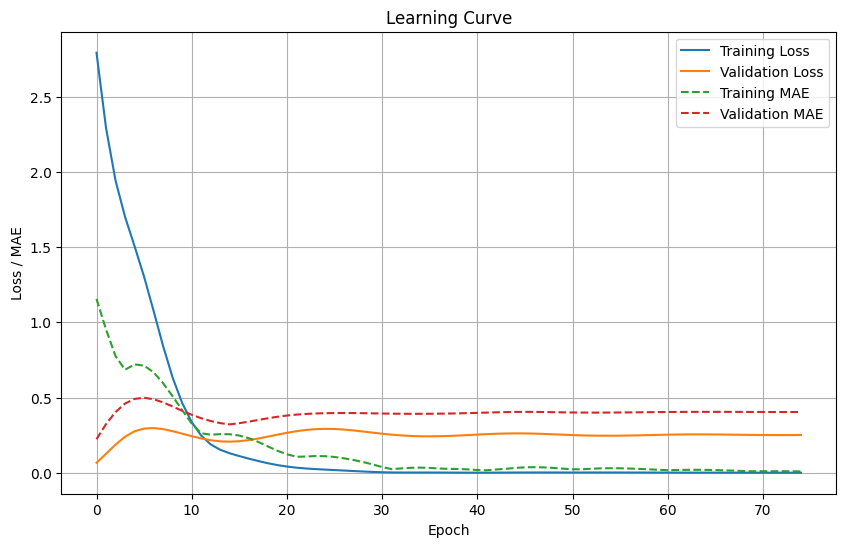

##LSTM (epoch: 75, batch size: 4)

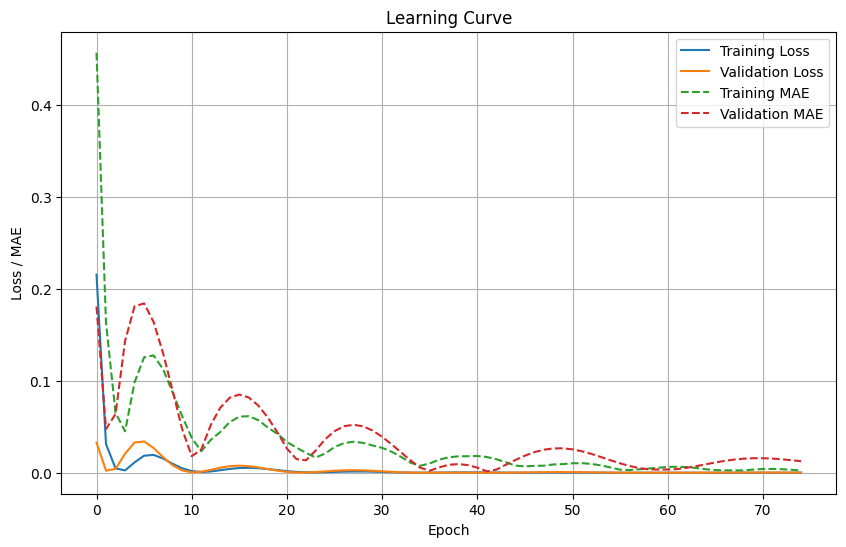

##GRU (ephoch: 75, batch size: 4)

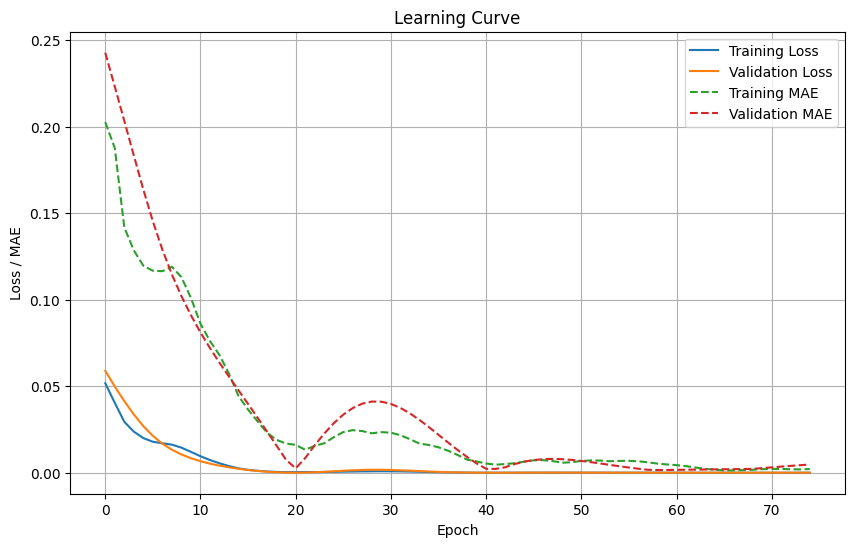

# Paper

*   Bayes optimal regressor vs NN
*   Neural Ordinary Integral Equations vs RNN
*   Barometric data noise distribution

